In [124]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [125]:
df_bikes = pd.read_csv("../csv/bikes.csv")
df_bike_types = pd.read_csv("../csv/bike_types.csv")
df_stations = pd.read_csv("../csv/stations.csv")
df_cities = pd.read_csv("../csv/cities.csv")
df_stations_status = pd.read_csv("../csv/stations_status.csv")
df_trips_small = pd.read_csv("../csv/trips_small.csv")

# 1) Data Exploration and Preprocessing Task

## Data Exploration
### Bikes

In [126]:
df_bikes.head()

,id,bike_type_id,computer_id
0,400481,196,83300002927
1,374044,204,7551171765
2,373778,204,7551140444
3,34749,14,0
4,88359,143,7551052355


In [127]:
df_bikes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88436 entries, 0 to 88435
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   id            88436 non-null  int64
 1   bike_type_id  88436 non-null  int64
 2   computer_id   88436 non-null  int64
dtypes: int64(3)
memory usage: 2.0 MB


### Bike_types

In [128]:
df_bike_types.head()

,id,vehicle_image,name,description,form_factor,rider_capacity,propulsion_type,max_range,battery_capacity
0,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [129]:
df_bike_types.info()
df_bike_types.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                121 non-null    int64  
 1   vehicle_image     91 non-null     object 
 2   name              91 non-null     object 
 3   description       51 non-null     object 
 4   form_factor       91 non-null     object 
 5   rider_capacity    91 non-null     float64
 6   propulsion_type   91 non-null     object 
 7   max_range         15 non-null     float64
 8   battery_capacity  22 non-null     float64
dtypes: float64(3), int64(1), object(5)
memory usage: 8.6+ KB


,id,rider_capacity,max_range,battery_capacity
count,121.000000,91.000000,15.0,22.000000
mean,134.454545,1.230769,60000.0,547.727273
std,77.738450,0.423659,0.0,61.638873
min,0.000000,1.000000,60000.0,500.000000
25%,72.000000,1.000000,60000.0,500.000000
50%,149.000000,1.000000,60000.0,500.000000
75%,201.000000,1.000000,60000.0,600.000000
max,254.000000,2.000000,60000.0,690.000000


In [130]:
print("Number of duplicates : ", df_bike_types.duplicated().sum())
print("Number of unique values in the 'name' column : ", len(df_bike_types["name"].unique()))

Number of duplicates :  0
Number of unique values in the 'name' column :  47


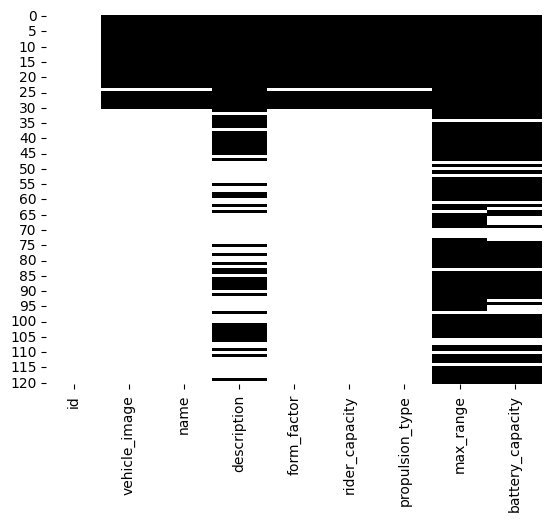

In [131]:
sns.heatmap(df_bike_types.isna(), cbar=False, cmap='binary')
plt.show()

In [132]:
df_bike_types["name"].unique()

array([nan, 'Comfort', 'Rower z fotelikiem dziecięcym', 'Tandem',
       'Elektricno kolo', 'e-CARGObike', 'Rowerek dziecięcy 6+',
       '3-rychlostní SMARTbike 2.0.', 'e-SMARTbike 2.0 with RFID',
       '28 Zoll - Tourenfahrrad', 'e-SMARTbike 2.0.',
       'Smartbike 2.0 (B) 2019', 'e-SMARTbike 1.0', 'UsedomRad',
       'UsedomRad Classic', '20 Zoll - Kinderfahrrad',
       '24 Zoll - Kinderfahrrad', 'Z wałem kardana',
       '7-rychlostní SMARTbike', 'e-Bike "LaBigi"', 'E-Bike',
       '7-rychlostní SMARTbike 2.0.', 'e-Cargobike', 'CARGObike',
       '8-rychlostní SMARTbike 2.0.', 'with Framelock',
       '8-rychlostní SMARTbike', 'CARGObike (3 wheels)',
       "+ Children's seat", '26 Zoll - Tourenfahrrad', 'Cargo', 'Unknown',
       'E-CLASSICbike SWAP', 'Handbike', 'Bike with child seat',
       'ebike [električni bicikl]', 'Dječja sjedalica', 'CLASSICbike 2.0',
       'Classic', 'Rower Trójkołowy', 'e-SMARTbike 2.0 (fixed battery)',
       'CLASSICbike', 'e-SMARTbike 2.0 RFID', 

[Text(0.5, 1.0, 'Count of Bike Types'),
 Text(0.5, 0, 'Count'),
 Text(0, 0.5, 'Bike Type')]

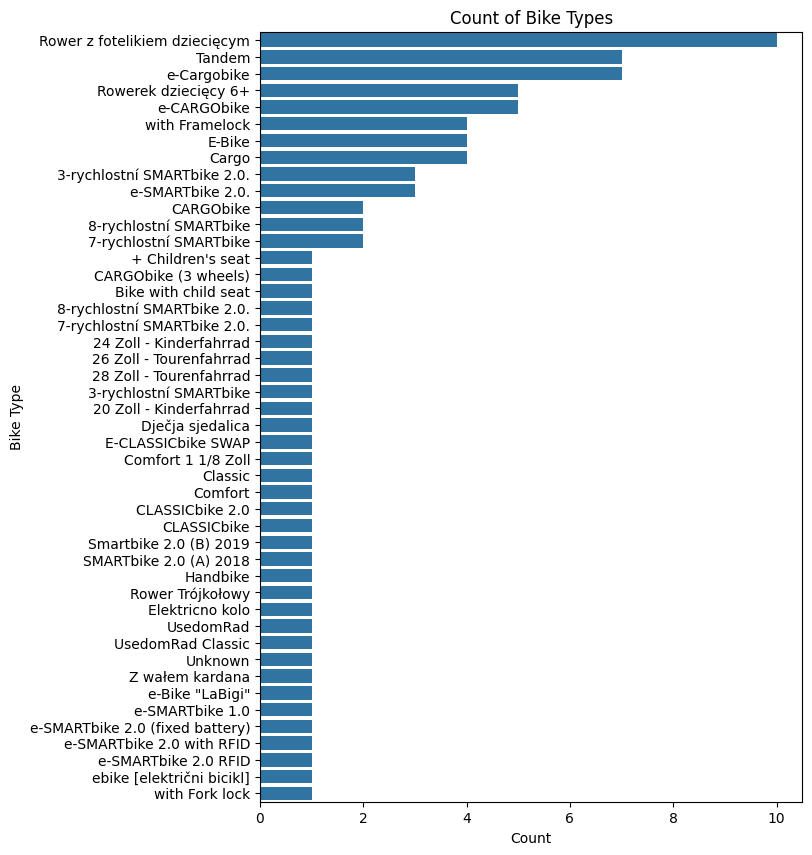

In [133]:
df_count = df_bike_types.groupby('name')["name"].count()
df_count = df_count.sort_values(ascending=False)

plt.figure(figsize=(7, 10))
sns_bar = sns.barplot(y=df_count.index, x=df_count.values)
sns_bar.set(
    title="Count of Bike Types",
    xlabel="Count", 
    ylabel="Bike Type"
)

In [134]:
df_bike_types["propulsion_type"].unique()

array([nan, 'human', 'electric_assist'], dtype=object)

In [135]:
propulsion = df_bike_types.groupby('propulsion_type')["propulsion_type"].count()
propulsion

propulsion_type
electric_assist    27
human              64
Name: propulsion_type, dtype: int64

Text(0.5, 1.0, 'Propulsion Type Distribution')

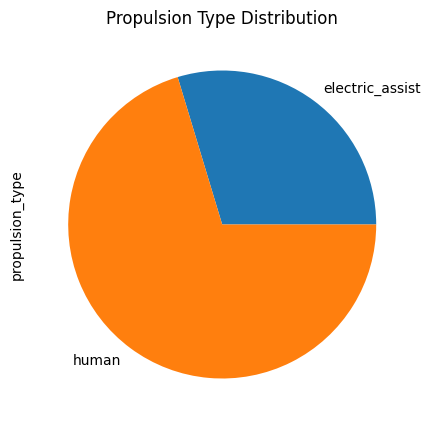

In [136]:
plt.figure(figsize=(5, 5))

propulsion.plot(kind="pie")
plt.title("Propulsion Type Distribution")

In [137]:
df_bike_types["form_factor"].unique()

array([nan, 'bicycle', 'cargo_bicycle', 'other'], dtype=object)

In [138]:
grouped_form = df_bike_types.groupby("form_factor").size().reset_index(name = "count")
grouped_form

,form_factor,count
0,bicycle,71
1,cargo_bicycle,19
2,other,1


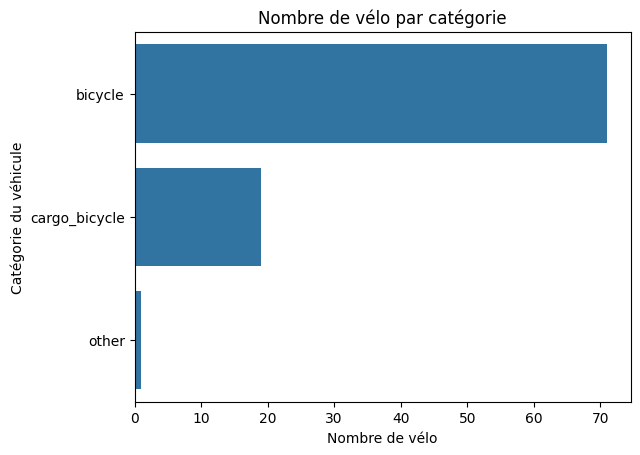

In [139]:
grouped_form = grouped_form.sort_values(["count"], ascending=False)

plt.figure()
sns_barplot = sns.barplot(grouped_form, x="count", y="form_factor")
sns_barplot.set(
    title = "Nombre de vélo par catégorie",
    xlabel = "Nombre de vélo",
    ylabel = "Catégorie du véhicule"
)
plt.show()

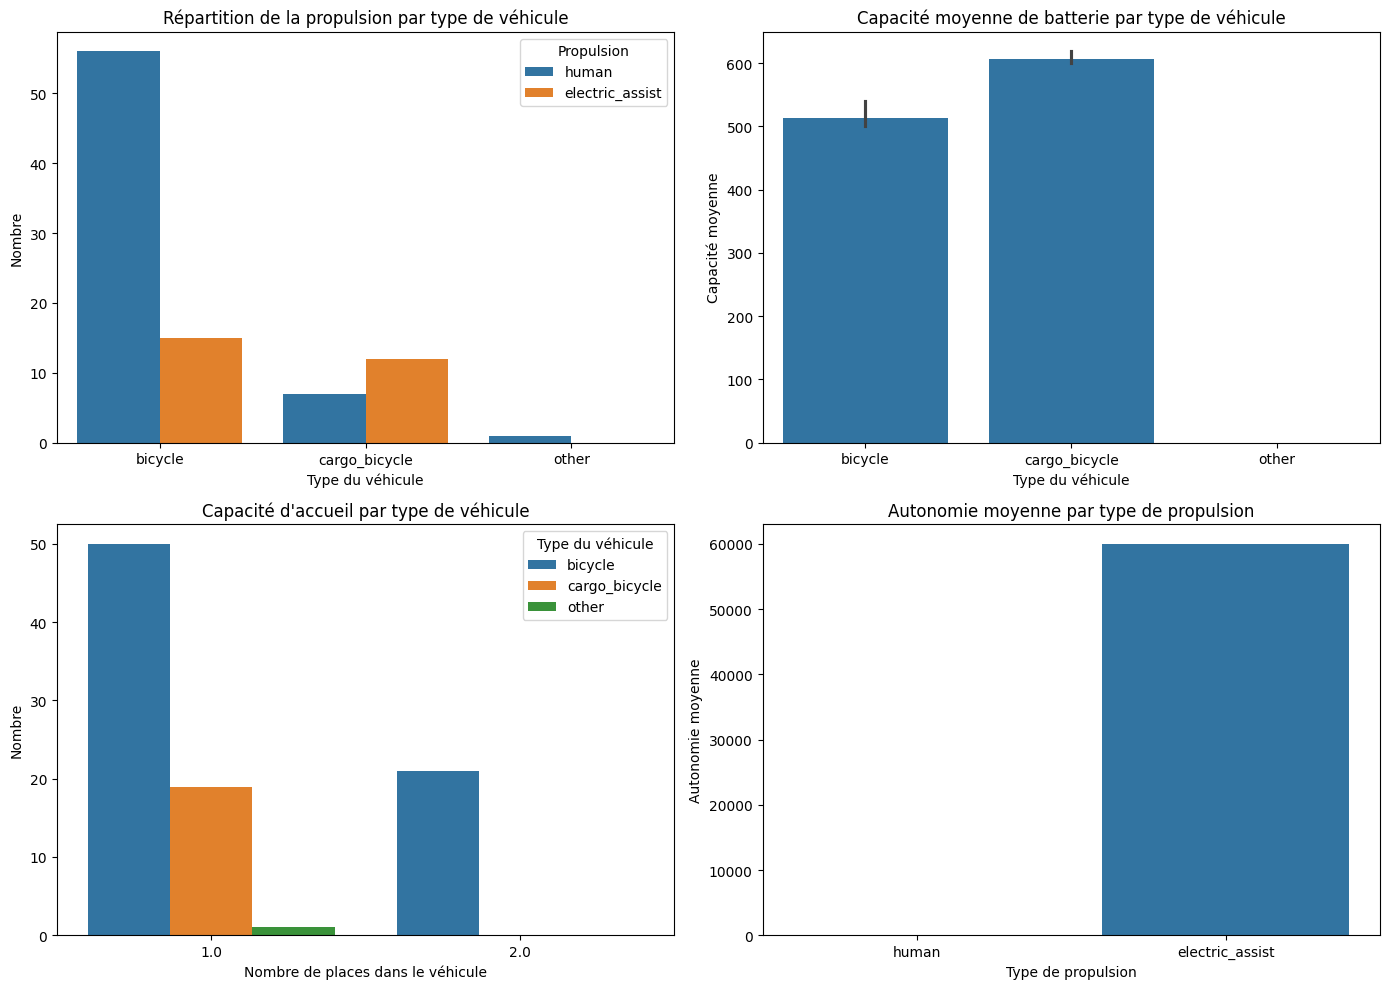

In [140]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df_bike_types, x='form_factor', hue='propulsion_type', ax=axes[0, 0])
axes[0, 0].set_title("Répartition de la propulsion par type de véhicule")
axes[0, 0].set_xlabel("Type du véhicule")
axes[0, 0].set_ylabel("Nombre")
axes[0, 0].legend(title="Propulsion")

sns.barplot(data=df_bike_types, x='form_factor', y='battery_capacity', estimator='mean', ax=axes[0, 1])
axes[0, 1].set_title("Capacité moyenne de batterie par type de véhicule")
axes[0, 1].set_xlabel("Type du véhicule")
axes[0, 1].set_ylabel("Capacité moyenne")

sns.countplot(data=df_bike_types, x='rider_capacity', hue='form_factor', ax=axes[1, 0])
axes[1, 0].set_title("Capacité d'accueil par type de véhicule")
axes[1, 0].set_xlabel("Nombre de places dans le véhicule")
axes[1, 0].set_ylabel("Nombre")
axes[1, 0].legend(title="Type du véhicule")

sns.barplot(data=df_bike_types, x='propulsion_type', y='max_range', estimator='mean', ax=axes[1, 1])
axes[1, 1].set_title("Autonomie moyenne par type de propulsion")
axes[1, 1].set_xlabel("Type de propulsion")
axes[1, 1].set_ylabel("Autonomie moyenne")

plt.tight_layout()
plt.show()

### Stations 

In [141]:
df_stations.head()

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836


In [142]:
df_stations.describe()

,id,city_id,app_number,place_type,bike_racks,special_racks,rack_locks,lon,lat
count,2.932000e+03,2932.000000,2932.000000,2932.000000,2932.000000,2932.000000,0.0,2932.000000,2932.000000
mean,4.116020e+07,480.171555,29985.929400,3.760914,6.033424,-0.011255,NaN,13.172182,49.272772
std,4.773764e+07,242.781001,61868.290176,6.894175,6.495116,0.486820,NaN,6.914270,4.342509
min,9.400000e+01,7.000000,0.000000,0.000000,0.000000,-10.000000,NaN,-15.758277,7.745476
25%,3.604443e+06,251.000000,4918.750000,0.000000,0.000000,0.000000,NaN,8.156823,47.955417
50%,2.531790e+07,527.000000,7907.500000,0.000000,6.000000,0.000000,NaN,14.314387,50.290478
75%,5.661078e+07,702.000000,48798.250000,0.000000,10.000000,0.000000,NaN,17.488668,51.602447
max,2.192360e+08,858.000000,999574.000000,27.000000,70.000000,12.000000,NaN,33.413632,57.005195


In [143]:
df_stations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   object 
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   object 
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), object(2)
memory usage: 252.1+ KB


In [144]:
# The column 'rack_locks' is null for all rows, so we can drop it from the dataframe to avoid unnecessary data.
df_stations = df_stations.drop('rack_locks', axis= 1)

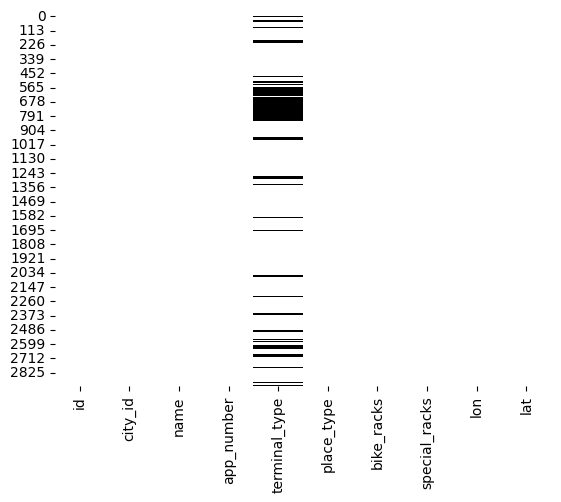

In [145]:
sns.heatmap(df_stations.isna(), cbar=False, cmap='binary')
plt.show()

In [146]:
print("Number of duplicate rows in df_stations:", df_stations.duplicated().sum())
print("Number of unique values in the 'terminal_type' column : ", len(df_stations["terminal_type"].unique()))

df_stations["terminal_type"].unique()

Number of duplicate rows in df_stations: 0
Number of unique values in the 'terminal_type' column :  11


array([nan, 'stele', 'smart_sign', 'sign', '7inch', 'free', 'character',
       'traffic_sign', 'mmt', 'terminal_sleek', 'pult'], dtype=object)

[Text(0.5, 1.0, 'Count of Terminal Types'),
 Text(0, 0.5, 'Terminal Type'),
 Text(0.5, 0, 'Count')]

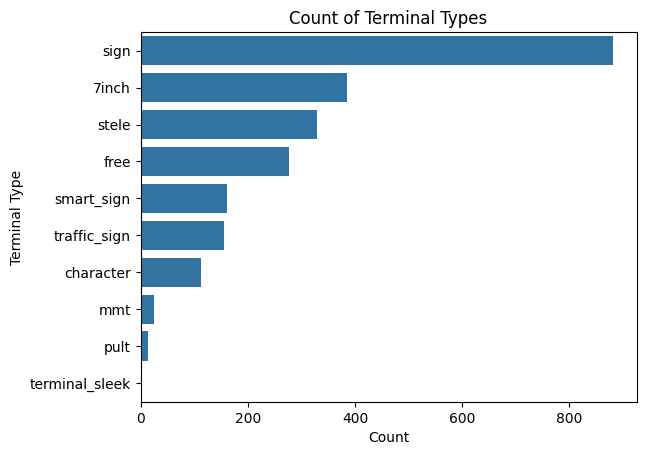

In [147]:
stations_count = df_stations['terminal_type'].value_counts()
sns_barplot = sns.barplot(
    y=stations_count.index,
    x=stations_count.values
    )
sns_barplot.set(
    title="Count of Terminal Types",
    ylabel="Terminal Type", 
    xlabel="Count"
)

### Cities

In [148]:
df_cities.head()

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [149]:
df_cities.describe()

,id,lat,lon
count,267.000000,267.000000,267.000000
mean,496.985019,49.067596,12.154192
std,232.772760,4.155125,7.029840
min,1.000000,27.815400,-15.518200
25%,314.000000,47.827850,8.306550
50%,537.000000,49.898000,13.744600
75%,691.500000,51.589750,16.831200
max,858.000000,57.690200,33.453500


In [150]:
df_cities.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  
 1   name                     267 non-null    object 
 2   lat                      267 non-null    float64
 3   lon                      267 non-null    float64
 4   timezone                 267 non-null    object 
 5   country                  267 non-null    object 
 6   return_to_official_only  267 non-null    bool   
dtypes: bool(1), float64(2), int64(1), object(3)
memory usage: 12.9+ KB


In [151]:
print("Number of unique city names:", len(df_cities["name"].unique()))
print("Number of unique timezones:", len(df_cities["timezone"].unique()))

Number of unique city names: 267
Number of unique timezones: 9


In [152]:
# Number of cities per country
df_cities["country"].value_counts()

country
DE    91
PL    53
CZ    25
AT    24
HR    19
ES    16
CH    13
SI    10
GB     9
CY     2
MT     1
SK     1
SE     1
IT     1
LV     1
Name: count, dtype: int64

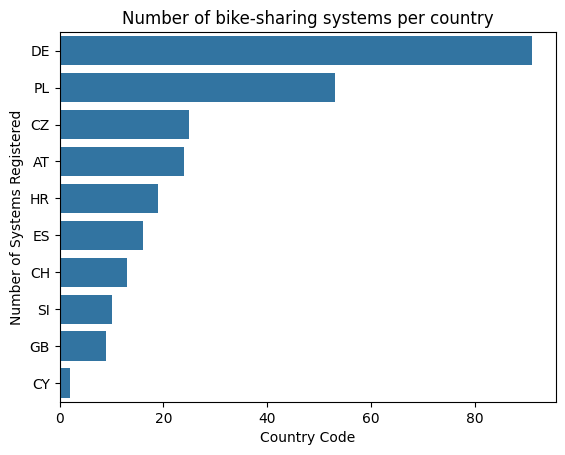

In [153]:
# Vizualization 
cities_top = df_cities["country"].value_counts().reset_index().head(10)

sns_bar = sns.barplot(
    data=cities_top,
    x="count",
    y="country"
)

sns_bar.set(
    title="Number of bike-sharing systems per country",
    xlabel="Country Code", 
    ylabel="Number of Systems Registered"
)

plt.show()

In [154]:
official_only = df_cities.groupby("return_to_official_only")["return_to_official_only"].count()
official_only

return_to_official_only
False     67
True     200
Name: return_to_official_only, dtype: int64

Text(0.5, 1.0, 'Distribution of Return to Official Only')

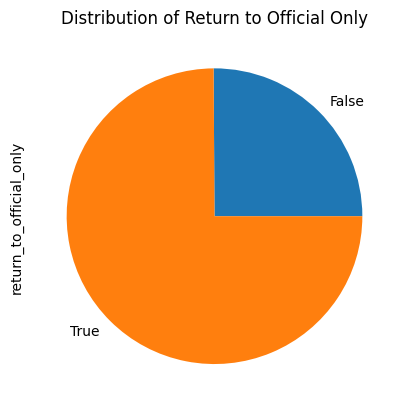

In [155]:
official_only.plot(kind='pie')
plt.title("Distribution of Return to Official Only")

### Stations Status

In [156]:
df_stations_status.head()

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False


In [157]:
df_stations_status.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2925967 entries, 0 to 2925966
Data columns (total 8 columns):
 #   Column                   Dtype  
---  ------                   -----  
 0   station_id               int64  
 1   time                     float64
 2   bikes                    int64  
 3   booked_bikes             int64  
 4   bikes_available_to_rent  int64  
 5   free_racks               int64  
 6   free_special_racks       int64  
 7   maintenance              bool   
dtypes: bool(1), float64(1), int64(6)
memory usage: 159.1 MB


In [158]:
# 1. Convert numeric UTC timestamp (seconds) to UTC datetime
df_stations_status['datetime'] = pd.to_datetime(df_stations_status['time'], unit='s', utc=True)

# 2. Extract separate numeric day and hour columns
df_stations_status['day_of_month'] = df_stations_status['datetime'].dt.day         # 1 to 31
df_stations_status['day_of_week']  = df_stations_status['datetime'].dt.day_name()   # e.g., 'Monday'
df_stations_status['hour']         = df_stations_status['datetime'].dt.hour       # 0 to 23

df_stations_status.head(10)

,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance,datetime,day_of_month,day_of_week,hour
0,101896428,1.661530e+09,2,0,2,0,0,False,2022-08-26 16:14:01+00:00,26,Friday,16
1,54643,1.661531e+09,1,0,1,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
2,6201611,1.661531e+09,3,0,3,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
3,294346,1.661531e+09,8,0,8,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
4,781866,1.661531e+09,1,1,0,5,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
5,137700,1.661531e+09,15,0,15,1,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
6,50464,1.661531e+09,3,0,3,3,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
7,6290772,1.661531e+09,3,0,3,1,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
8,8341045,1.661531e+09,10,0,10,0,0,False,2022-08-26 16:15:01+00:00,26,Friday,16
9,3581060,1.661531e+09,7,0,7,8,6,False,2022-08-26 16:15:01+00:00,26,Friday,16


### Trips Small

In [159]:
df_trips_small.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


In [160]:
df_trips_small.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1161376 entries, 0 to 1161375
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   bike_id           1161376 non-null  int64  
 1   city_id           1161376 non-null  int64  
 2   time_start        1161376 non-null  float64
 3   lon_start         1161376 non-null  float64
 4   lat_start         1161376 non-null  float64
 5   lon_end           1161376 non-null  float64
 6   lat_end           1161376 non-null  float64
 7   station_id_start  1072161 non-null  float64
 8   station_id_end    1039472 non-null  float64
 9   battery_start     168532 non-null   float64
 10  battery_end       168641 non-null   float64
 11  duration          1161376 non-null  float64
 12  distance          1161376 non-null  float64
dtypes: float64(11), int64(2)
memory usage: 115.2 MB


The number of missing values in the 'battery_start' and 'battery_end' columns is very high. However, these columns are relevant only for electric bikes, so we have to look at the number of missing values in these columns for electric bikes only. This is done after merging all the dataframe together.


In [161]:
df_trips_small.describe()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
count,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,1.161376e+06,1.072161e+06,1.039472e+06,168532.000000,168641.000000,1.161376e+06,1.161376e+06
mean,2.265793e+05,5.179235e+02,1.676599e+09,1.143184e+01,4.941432e+01,1.143162e+01,4.941407e+01,4.223439e+07,4.236450e+07,80.988697,76.688996,1.256241e+03,1.791774e+03
std,1.996392e+05,2.374043e+02,9.407677e+06,7.320269e+00,3.707710e+00,7.320443e+00,3.708131e+00,4.759018e+07,4.793164e+07,21.384192,22.615122,1.980838e+03,1.495191e+03
min,3.346000e+03,7.000000e+00,1.661525e+09,-1.560567e+01,2.774058e+01,-1.560567e+01,2.774058e+01,9.400000e+01,9.400000e+01,0.000000,0.000000,1.210000e+02,5.001365e+01
25%,5.962500e+04,3.310000e+02,1.666845e+09,7.165686e+00,4.717771e+01,7.165686e+00,4.717771e+01,5.669128e+06,5.445517e+06,66.000000,61.000000,4.800000e+02,8.851685e+02
50%,8.881000e+04,5.480000e+02,1.678902e+09,1.019364e+01,5.027373e+01,1.018726e+01,5.026997e+01,2.072905e+07,1.982877e+07,89.000000,83.000000,7.200000e+02,1.346711e+03
75%,4.001430e+05,7.170000e+02,1.685627e+09,1.745811e+01,5.174006e+01,1.745811e+01,5.173991e+01,7.251972e+07,7.279031e+07,100.000000,97.000000,1.200000e+03,2.238540e+03
max,8.400540e+05,8.580000e+02,1.689458e+09,3.398531e+01,5.708158e+01,3.398632e+01,5.708158e+01,2.192360e+08,2.146129e+08,100.000000,100.000000,2.874000e+04,1.999946e+04


## Merge tables

In [162]:
# Assembling a complete dataframe with trips, bikes and bike types information
bike_sub = df_bikes[['id', 'bike_type_id']]
bike_type_sub = df_bike_types[['id', 'name', 'form_factor', 'propulsion_type', 'max_range', "battery_capacity"]]

trips_with_bikes = pd.merge(df_trips_small, bike_sub, left_on='bike_id', right_on='id', how='left')

complete_df = pd.merge(trips_with_bikes, bike_type_sub, left_on="bike_type_id", right_on="id", how="left")
complete_df = complete_df.drop(columns=['id_x', 'id_y'])

complete_df

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,bike_type_id,name,form_factor,propulsion_type,max_range,battery_capacity
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806,15,with Fork lock,bicycle,human,NaN,NaN
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764,15,with Fork lock,bicycle,human,NaN,NaN
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620,15,with Fork lock,bicycle,human,NaN,NaN
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250,15,with Fork lock,bicycle,human,NaN,NaN
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993,15,with Fork lock,bicycle,human,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1161371,840054,679,1.684753e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,96.0,1320.0,3061.891906,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161372,840054,679,1.685088e+09,-3.166644,51.446057,-3.163247,51.465538,6270602.0,88102363.0,100.0,97.0,780.0,2178.941052,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161373,840054,679,1.686059e+09,-3.174022,51.438833,-3.163247,51.465538,30005988.0,88102363.0,100.0,95.0,900.0,3061.891906,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0
1161374,840054,679,1.686121e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,87.0,75.0,1020.0,4260.899309,182,e-SMARTbike 2.0 with RFID,bicycle,electric_assist,60000.0,500.0


In [163]:
# Filter to get only electric bikes and see if we can drop the columns battery_start and battery_end 
electric_df = complete_df.groupby("propulsion_type")
electric_df = complete_df[complete_df["propulsion_type"] == "electric"]

electric_df.info()

# We can't

<class 'pandas.core.frame.DataFrame'>
Index: 0 entries
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   bike_id           0 non-null      int64  
 1   city_id           0 non-null      int64  
 2   time_start        0 non-null      float64
 3   lon_start         0 non-null      float64
 4   lat_start         0 non-null      float64
 5   lon_end           0 non-null      float64
 6   lat_end           0 non-null      float64
 7   station_id_start  0 non-null      float64
 8   station_id_end    0 non-null      float64
 9   battery_start     0 non-null      float64
 10  battery_end       0 non-null      float64
 11  duration          0 non-null      float64
 12  distance          0 non-null      float64
 13  bike_type_id      0 non-null      int64  
 14  name              0 non-null      object 
 15  form_factor       0 non-null      object 
 16  propulsion_type   0 non-null      object 
 17  max_range     

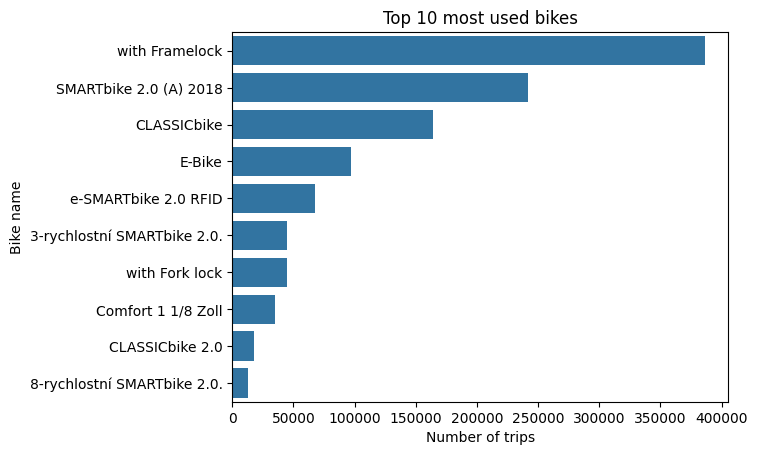

In [164]:
top_bikes = complete_df['name'].value_counts().head(10).reset_index()
top_bikes.columns = ['name', 'count']

plt.figure()
top_bikes_barplot = sns.barplot(data=top_bikes, x='count', y='name')
top_bikes_barplot.set_title("Top 10 most used bikes")
top_bikes_barplot.set_xlabel("Number of trips")
top_bikes_barplot.set_ylabel("Bike name")
plt.show()

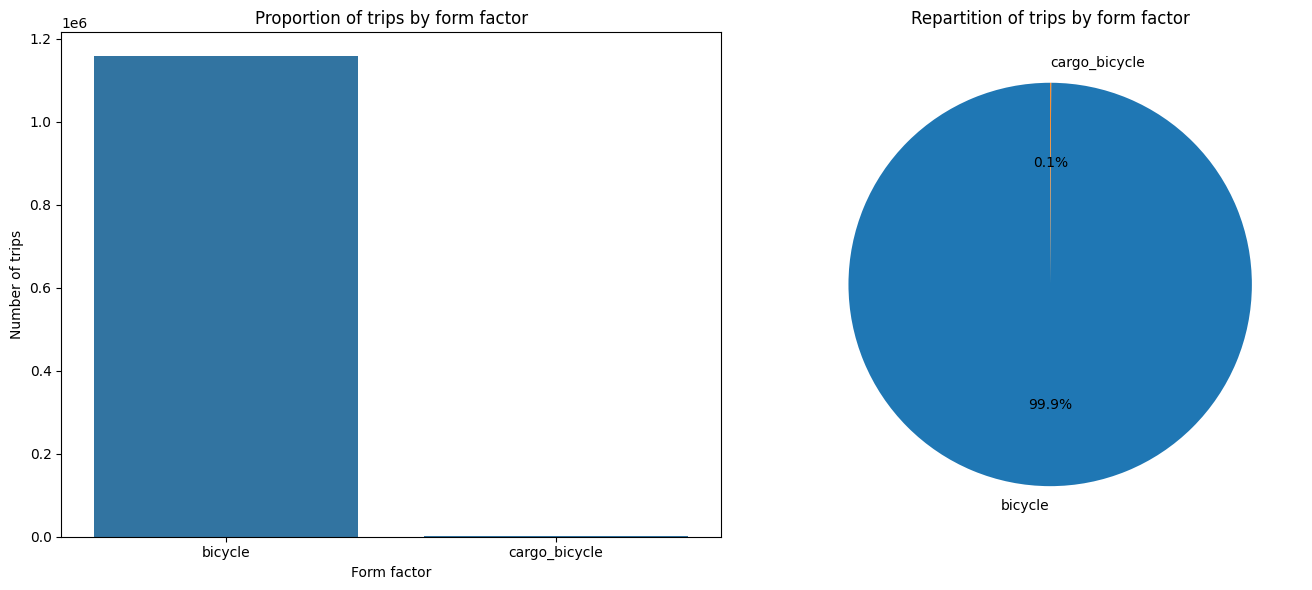

In [165]:
form_counts = complete_df['form_factor'].value_counts().reset_index()
form_counts.columns = ['form_factor', 'count']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(data=form_counts, x='form_factor', y='count', ax=axes[0])
axes[0].set_title("Proportion of trips by form factor")
axes[0].set_xlabel("Form factor")
axes[0].set_ylabel("Number of trips")

complete_df['form_factor'].value_counts().plot(
    kind='pie', 
    autopct='%1.1f%%', 
    startangle=90, 
    ax=axes[1]
)
axes[1].set_title("Repartition of trips by form factor")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [166]:
# Unsupervised Tasks: Bike Trip and Stations Profiles
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

df_trips_small.head()


,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


Utilisez les coordonnées spatiales (lon_start, lat_start, lon_end, lat_end) pour regrouper les trajets géographiquement et identifier les pôles d'attractivité.
- **Départs & Coordonnées :** Utilisation de `groupby('station_id_start')` pour compter le nombre de départs par station et extraire leurs coordonnées spatiales (`lat`, `lon`).
- **Arrivées :** Utilisation de `groupby('station_id_end')` pour compter le nombre d'arrivées, afin de mesurer la véritable force d'attraction de la station.
- **Fusion :** Jointure (`join`)pour réunir ces données.
- **Nouvelles variables :** Calcul du *Volume total* (départs + arrivées) et du *Ratio * (arrivées / départs) pour distinguer les zones résidentielles (émettrices) des zones d'activité (réceptrices).

In [167]:
# Clustering géographique en utilisant dataset trips

departs = df_trips_small.groupby('station_id_start').agg(
    nb_departs=('bike_id', 'count'),
    lat=('lat_start', 'first'),
    lon=('lon_start', 'first')
)

arrivees = df_trips_small.groupby('station_id_end').agg(
    nb_arrivees=('bike_id', 'count')
)

df_stations = departs.join(arrivees, how='inner')
df_stations['volume_total'] = df_stations['nb_departs'] + df_stations['nb_arrivees']
df_stations['ratio_attractivite'] = df_stations['nb_arrivees'] / (df_stations['nb_departs'] + 1e-5)


In [168]:
departs.head()

,nb_departs,lat,lon
station_id_start,,,
94.0,19,47.906200,16.698299
522.0,68,47.942251,16.846504
556.0,91,47.928737,16.834939
568.0,28,47.941338,16.746265
572.0,6,47.754617,16.697245


In [169]:
arrivees.head()

,nb_arrivees
station_id_end,
94.0,14
522.0,59
556.0,79
568.0,18
572.0,10


In [170]:
df_stations.head()

,nb_departs,lat,lon,nb_arrivees,volume_total,ratio_attractivite
94.0,19,47.906200,16.698299,14,33,0.736842
522.0,68,47.942251,16.846504,59,127,0.867647
556.0,91,47.928737,16.834939,79,170,0.868132
568.0,28,47.941338,16.746265,18,46,0.642857
572.0,6,47.754617,16.697245,10,16,1.666664


In [171]:
X = df_stations[['lat', 'lon', 'volume_total', 'ratio_attractivite']]
X_scaled = StandardScaler().fit_transform(X)

In [177]:
kmeans = KMeans(n_clusters=2, random_state=42)
df_stations['cluster_attractivite'] = kmeans.fit_predict(X_scaled)

In [180]:
df_stations['cluster_attractivite'].value_counts()

cluster_attractivite
0    3002
1     615
Name: count, dtype: int64

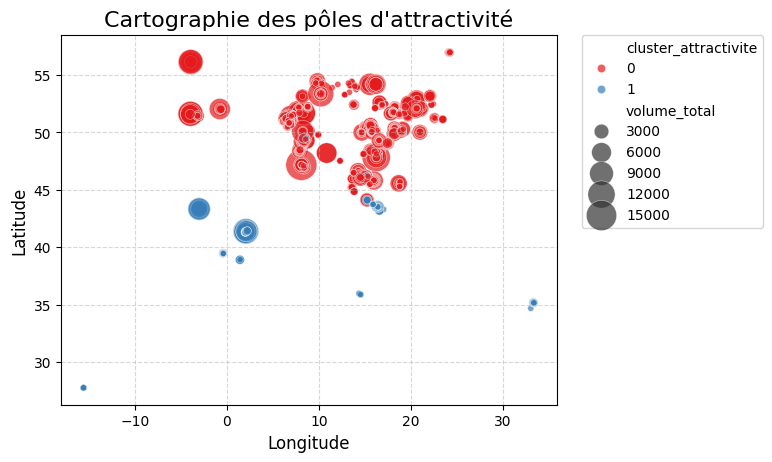

In [182]:
sns.scatterplot(
    data=df_stations,
    x='lon',                   # Axe X : Longitude
    y='lat',                   # Axe Y : Latitude
    hue='cluster_attractivite',# Couleur : selon le groupe K-Means (0, 1 ou 2)
    size='volume_total',       # Taille du point : selon l'activité totale
    sizes=(20, 500),           # Plage de taille des points
    palette='Set1',            # Palette de couleurs bien distinctes
    alpha=0.7                  # Transparence pour gérer les superpositions
)
plt.title("Cartographie des pôles d'attractivité", fontsize=16)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)

plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()